# UK MET Office Weather Data
-----------------------------
-----------------------------

## First, we import some tools or libraries needed

In [42]:
import numpy as np 
import pandas as pd
from sklearn.linear_model import LinearRegression
import streamlit as st
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
print('All imported!')

All imported!


## Load the Shawbury Data from GitHub

In [2]:
# save the link to the data
data_link = 'https://raw.githubusercontent.com/Lawrence-Krukrubo/wlv-weather-ai-demo/refs/heads/main/weather_demo_shawbury_2010_2019.csv'

In [5]:
# let's load the raw data into a pandas dataframe table

shawbury_df = pd.read_csv(data_link)

In [6]:
# let's see the first 12 data points for 2010

shawbury_df.head(12)

,station,year,month,tmax,tmin,rain,sun,af
0,shawbury,2010,1,4.0,-1.9,57.4,61.7,20
1,shawbury,2010,2,5.9,-0.9,25.8,53.0,18
2,shawbury,2010,3,10.4,1.1,35.2,122.5,12
3,shawbury,2010,4,14.0,3.0,19.6,178.8,6
4,shawbury,2010,5,15.4,5.6,37.0,183.5,1
5,shawbury,2010,6,20.8,9.7,38.6,227.9,0
6,shawbury,2010,7,20.7,12.8,74.6,86.1,0
7,shawbury,2010,8,19.1,10.6,48.2,135.7,0
8,shawbury,2010,9,18.0,9.6,59.0,131.8,0
9,shawbury,2010,10,14.0,5.5,67.8,113.8,4


In [52]:
# let's see the last 12 data points for 2019

shawbury_df.tail(12)

,station,year,month,tmax,tmin,rain,sun,af
108,shawbury,2019,1,6.9,0.7,35.2,36.3,15
109,shawbury,2019,2,11.3,1.2,32.8,104.2,11
110,shawbury,2019,3,11.6,3.6,53.4,109.6,4
111,shawbury,2019,4,13.9,3.9,38.4,134.0,3
112,shawbury,2019,5,16.0,6.1,26.8,171.8,1
113,shawbury,2019,6,18.2,9.9,115.4,111.7,0
114,shawbury,2019,7,21.8,12.5,39.2,160.6,0
115,shawbury,2019,8,21.5,12.9,76.4,161.2,0
116,shawbury,2019,9,18.5,9.5,120.6,136.3,0
117,shawbury,2019,10,13.3,5.8,116.6,76.1,2


* **tmax** = Mean daily maximum temperature $4.0 °C  - 24.2 °C$
* **tmin** = Mean daily minimum temperature $-1.9 °C - 12.9 °C$
* **rain** =  Total monthly rainfall $8.4\text{ mm} - 163.6\text{ mm}$
* **sun** = Total monthly sunshine duration $31.8\text{ hrs} - 263.1\text{ hrs}$
* **af** = Air frost days (minimum temp $< 0\text{ °C}$) $0 - 20\text{ days}$

In [4]:
# let's see how many observations or data points we have;

shawbury_df.shape

(120, 8)

In [14]:
shawbury_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   station  120 non-null    object 
 1   year     120 non-null    int64  
 2   month    120 non-null    int64  
 3   tmax     120 non-null    float64
 4   tmin     120 non-null    float64
 5   rain     120 non-null    float64
 6   sun      120 non-null    float64
 7   af       120 non-null    int64  
dtypes: float64(4), int64(3), object(1)
memory usage: 7.6+ KB


## Visualizing the data

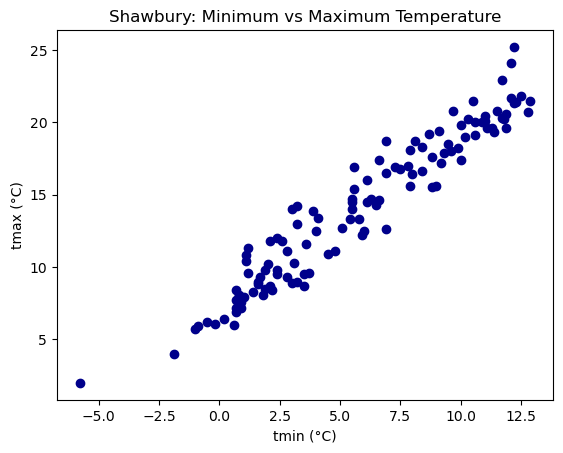

In [21]:
plt.scatter(x='tmin', y='tmax', c="DarkBlue", data=shawbury_df)
plt.title("Shawbury: Minimum vs Maximum Temperature")
plt.xlabel("tmin (°C)")
plt.ylabel("tmax (°C)")
plt.show()

## AI Task - Predict `tmax` from `tmin` - Simple Linear regression

In [10]:
# We isolate our feature (X) and our target (y) 
# Note: X must be a 2D dataframe [['tmin']] 

X = shawbury_df[['tmin']] 
y = shawbury_df['tmax'] 

# Create and train the model 
model_tmax = LinearRegression() 

# --- STUDENT TASK: Train the AI on tmin and tmax --- 
model_tmax.fit(X, y) 

print("AI Model 1 trained! It has learned how tmin predicts tmax.")

AI Model 1 trained! It has learned how tmin predicts tmax.


Slope (m): 1.1853
Intercept (c): 7.2356


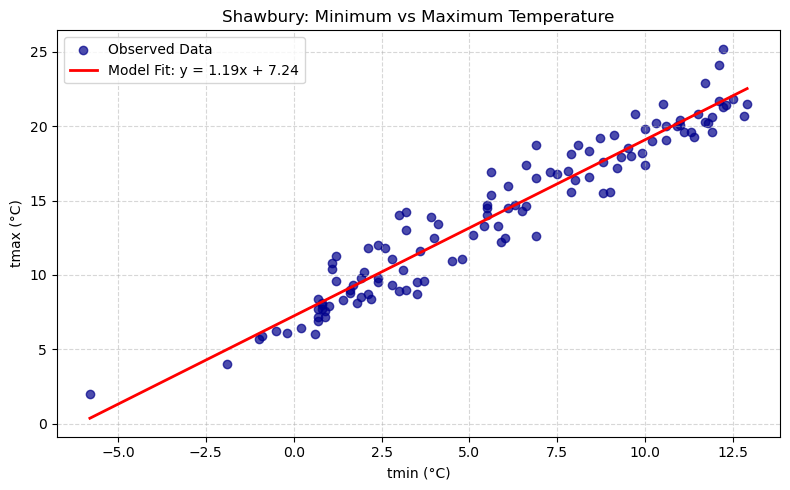

In [33]:
x_line = np.linspace(shawbury_df['tmin'].min(), shawbury_df['tmin'].max(), 100).reshape(-1, 1)
y_line = model_tmax.predict(x_line)

print(f"Slope (m): {model_tmax.coef_[0]:.4f}")
print(f"Intercept (c): {model_tmax.intercept_:.4f}")

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(x='tmin', y='tmax', c="DarkBlue", data=shawbury_df, label='Observed Data', alpha=0.7)
plt.plot(x_line, y_line, color='red', linewidth=2, label=f'Model Fit: y = {model_tmax.coef_[0]:.2f}x + {model_tmax.intercept_:.2f}')
plt.title("Shawbury: Minimum vs Maximum Temperature")
plt.xlabel("tmin (°C)")
plt.ylabel("tmax (°C)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
#plt.savefig('shawbury_regression.png', dpi=150)
#plt.close()

## Interactive Test — Predict Today's High

#### Let students test their model with any morning low:

In [34]:
# Student picks a morning low (tmin) 

morning_tmin = 4.5 # Try -2.0, 5.0, or 12.0 °C 

# Ask AI to predict the afternoon high (tmax) 

pred_tmax = model_tmax.predict([[morning_tmin]]) 

print(f'If morning ave min temp is {morning_tmin}, AI predicts ave max temp to be: {np.round(pred_tmax, 1)}')

If morning ave min temp is 4.5, AI predicts ave max temp to be: [12.6]


## (Bonus): Predict Air Frost Days (`af`) - Multiple Linear Regression

#### If the students finish early, we can train a second model predicting **af** **(air frost days)** using **both** **tmin** **and** **tmax**:

In [40]:
# Multiple features predicting frost days 

X_frost = shawbury_df[['tmin', 'tmax']] 
y_frost = shawbury_df['af']

model_frost = LinearRegression() 
model_frost.fit(X_frost, y_frost) 

# Test with a cold month vs warm month 

test_tmin = -1.0 
test_tmax = 6.0 

pred_frost = model_frost.predict([[test_tmin, test_tmax]]) 

# Ensure frost days don't display as negative 
pred_frost = max(0, np.round(pred_frost)) 

print(f"At tmin={test_tmin} C and tmax={test_tmax} C ; Predicted Air Frost Days: {pred_frost} days")

At tmin=-1.0 C and tmax=6.0 C ; Predicted Air Frost Days: [13.] days


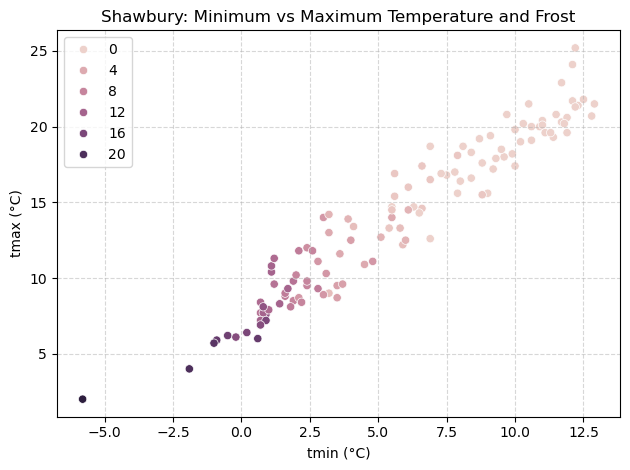

In [51]:
sns.scatterplot(x='tmin', y='tmax', hue='af', data=shawbury_df)
plt.title("Shawbury: Minimum vs Maximum Temperature and Frost")
plt.xlabel("tmin (°C)")
plt.ylabel("tmax (°C)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()